# Walmart M5 Demand Forecasting and Inventory Planning
**Goal:** forecast weekly demand for the best-selling food products in a Texas Walmart store, pick the most accurate method for each product, and turn the forecasts into safety stock and reorder points.

| Part | What it does |
|---|---|
| 1. Prepare the data | Daily sales → weekly sales for the top products |
| 2. Explore | Trends, seasonality, SNAP days and holidays |
| 3. Forecast | Compare 3 methods on a 12-week holdout |
| 4. Inventory plan | Safety stock, reorder points and the service level trade-off |

**Before you start:** download `sales_train_evaluation.csv`, `calendar.csv` and `sell_prices.csv` from the Kaggle M5 Forecasting Accuracy competition and put them in the same folder as this notebook. Run the cells top to bottom (Shift + Enter).

## Settings you can change

In [1]:
STORE = "TX_1"          # CA_1..CA_4, TX_1..TX_3, WI_1..WI_3
CATEGORY = "FOODS"      # FOODS, HOUSEHOLD, HOBBIES
TOP_N = 20              # number of best-selling products
TEST_WEEKS = 12         # weeks hidden to test the forecasts
LEAD_TIME_WEEKS = 2     # weeks between placing an order and receiving it

## Load the tools

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings
warnings.filterwarnings("ignore")

# Part 1: Prepare the data

## Step 1: Open the files
`sales` has units sold per product per day. `cal` turns day codes like d_1 into real dates, and also has Walmart weeks, holidays and SNAP days.

In [3]:
sales = pd.read_csv("sales_train_evaluation.csv")
cal = pd.read_csv("calendar.csv")
cal["date"] = pd.to_datetime(cal["date"])

print("Rows in sales file:", len(sales))

Rows in sales file: 30490


## Step 2: Keep one store and one category

In [4]:
df = sales[sales["store_id"] == STORE]
df = df[df["cat_id"] == CATEGORY]

print("Products kept:", len(df))

Products kept: 1437


## Step 3: Turn the day columns into rows
Each day (d_1, d_2 ...) is a column. `melt` stacks them so each row is one product on one day. Then we join the calendar to add the real date, Walmart week, holidays and SNAP days.

In [5]:
day_cols = []
for col in df.columns:
    if col.startswith("d_"):
        day_cols.append(col)

long = df.melt(id_vars="item_id", value_vars=day_cols, var_name="d", value_name="units")
long = long.merge(cal, on="d")

long.head()

,item_id,d,units,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,FOODS_1_001,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
1,FOODS_1_002,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
2,FOODS_1_003,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
3,FOODS_1_004,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0
4,FOODS_1_005,d_1,2,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,0,0


## Step 4: Remove incomplete weeks
A Walmart week runs Saturday to Friday. The last week in the data has only 2 days, which would look like a sales drop, so we keep only weeks with all 7 days.

In [6]:
days_in_week = long.groupby("wm_yr_wk")["date"].nunique()
full_weeks = days_in_week[days_in_week == 7].index
long = long[long["wm_yr_wk"].isin(full_weeks)]

print("Full weeks kept:", len(full_weeks))

Full weeks kept: 277


## Step 5: Add up daily sales into weekly sales

In [7]:
weekly = long.groupby(["item_id", "wm_yr_wk"])["units"].sum().reset_index()

week_dates = long.groupby("wm_yr_wk")["date"].min().reset_index()
week_dates = week_dates.rename(columns={"date": "week_start"})
weekly = weekly.merge(week_dates, on="wm_yr_wk")

weekly.head()

,item_id,wm_yr_wk,units,week_start
0,FOODS_1_001,11101,2,2011-01-29
1,FOODS_1_002,11101,0,2011-01-29
2,FOODS_1_003,11101,1,2011-01-29
3,FOODS_1_004,11101,0,2011-01-29
4,FOODS_1_005,11101,9,2011-01-29


## Step 6: Keep the best-selling products

In [8]:
totals = weekly.groupby("item_id")["units"].sum().sort_values(ascending=False)
top_items = list(totals.head(TOP_N).index)

print(top_items)

['FOODS_3_586', 'FOODS_3_090', 'FOODS_3_555', 'FOODS_3_252', 'FOODS_3_587', 'FOODS_3_714', 'FOODS_3_202', 'FOODS_3_694', 'FOODS_3_723', 'FOODS_3_607', 'FOODS_3_377', 'FOODS_3_681', 'FOODS_3_226', 'FOODS_2_181', 'FOODS_3_541', 'FOODS_3_808', 'FOODS_3_455', 'FOODS_3_234', 'FOODS_3_462', 'FOODS_3_635']


## Step 7: One column per product
Each row is a week and each column is a product, so `wide["FOODS_3_586"]` gives one product's full weekly history.

In [9]:
weekly = weekly[weekly["item_id"].isin(top_items)]
wide = weekly.pivot(index="week_start", columns="item_id", values="units").fillna(0)

print("Weeks:", len(wide), "| Products:", len(wide.columns))

Weeks: 277 | Products: 20


# Part 2: Explore the patterns

## Step 8: Weekly sales for the top 5 products
The faint line is weekly sales. The bold line is a 4-week moving average that smooths out the noise.

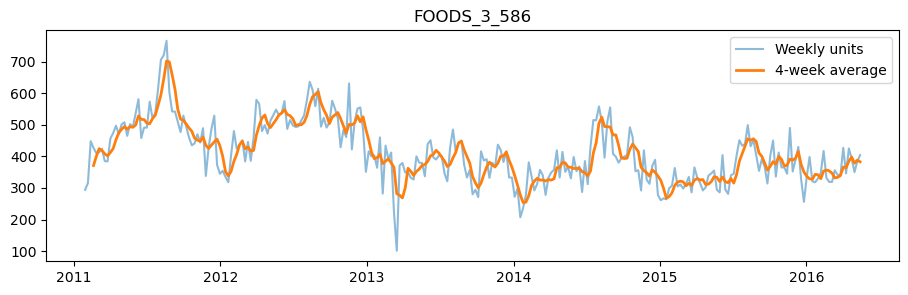

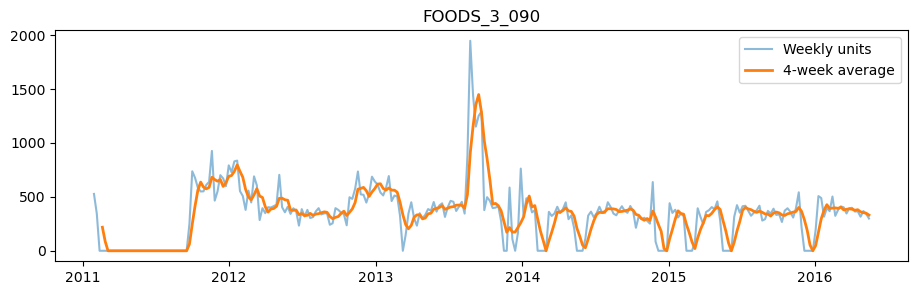

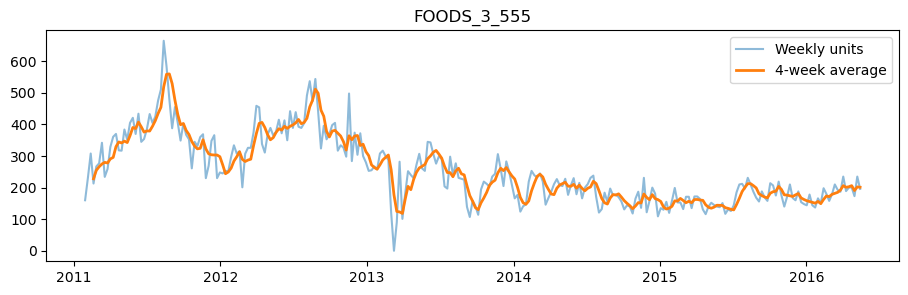

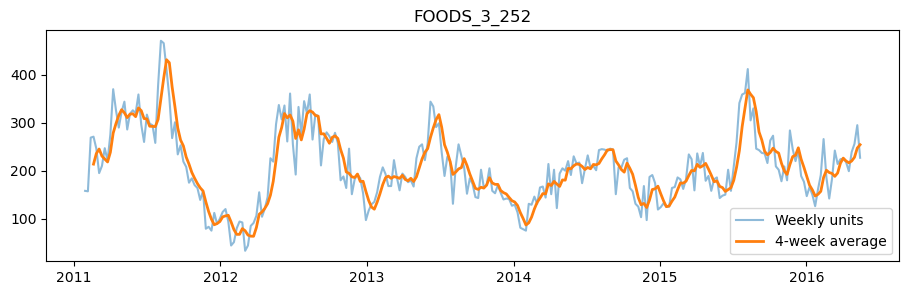

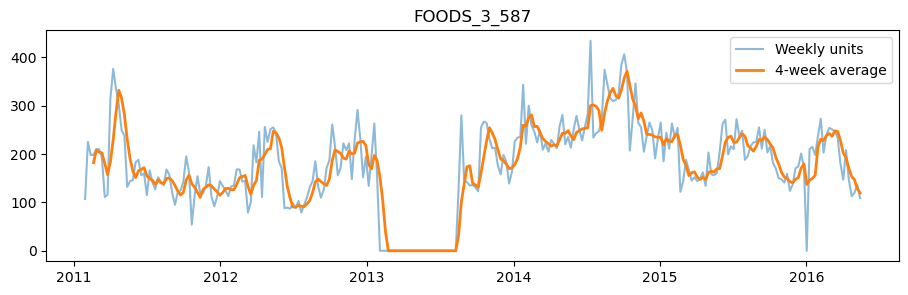

In [10]:
for item in top_items[:5]:
    plt.figure(figsize=(11, 3))
    plt.plot(wide[item], alpha=0.5, label="Weekly units")
    plt.plot(wide[item].rolling(4).mean(), linewidth=2, label="4-week average")
    plt.title(item)
    plt.legend()
    plt.show()

## Step 9: Split the top product into trend, season and noise
- **Trend:** going up or down over the years
- **Seasonal:** the pattern that repeats every year
- **Resid:** random leftover

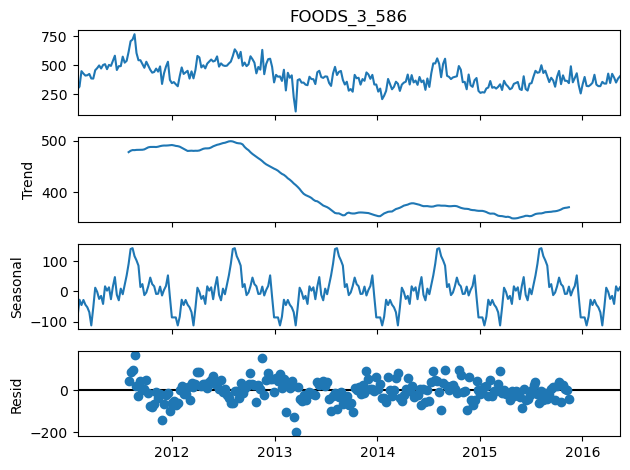

In [11]:
item = top_items[0]
parts = seasonal_decompose(wide[item], model="additive", period=52)
parts.plot()
plt.savefig("decomposition.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 10: Do SNAP days change sales?
`snap_TX = 1` means food stamp benefits could be used in Texas that day. We compare average daily units per product on SNAP days vs normal days.

In [12]:
top_long = long[long["item_id"].isin(top_items)].copy()

snap_avg = top_long.groupby("snap_TX")["units"].mean()
print(snap_avg.round(2))

snap_lift = (snap_avg[1] / snap_avg[0] - 1) * 100
print("SNAP days sell", round(snap_lift, 1), "% more than normal days")

snap_TX
0    19.98
1    21.76
Name: units, dtype: float64
SNAP days sell 8.9 % more than normal days


## Step 11: Do holidays and events change sales?
`event_name_1` is filled on event days (Super Bowl, Thanksgiving, Christmas...) and blank on normal days.

In [13]:
top_long["is_event"] = top_long["event_name_1"].notna()
normal_day = top_long[~top_long["is_event"]]["units"].mean()

by_event = top_long[top_long["is_event"]].groupby("event_name_1")["units"].mean()
by_event = ((by_event / normal_day - 1) * 100).sort_values()

print("Events with the biggest drop vs a normal day (%):")
print(by_event.round(1).head(5))
print()
print("Events with the biggest lift vs a normal day (%):")
print(by_event.round(1).tail(5))

Events with the biggest drop vs a normal day (%):
event_name_1
Christmas       -99.9
NewYear         -29.6
LentStart       -24.4
PresidentsDay   -15.8
StPatricksDay   -13.6
Name: units, dtype: float64

Events with the biggest lift vs a normal day (%):
event_name_1
Mother's day    27.9
LaborDay        40.6
Thanksgiving    53.9
Father's day    56.1
Easter          74.7
Name: units, dtype: float64


# Part 3: Forecast

## Step 12: The three forecasting methods
- **Moving average:** average of the last 4 weeks, used for every future week (the baseline)
- **Seasonal naive:** each future week = the same week last year
- **Holt-Winters:** learns the level, a fading trend and the yearly season. Needs 2 years of history; otherwise it falls back to simple exponential smoothing. Negative guesses are set to 0.

In [14]:
def moving_average_forecast(train, weeks):
    guess = train.tail(4).mean()
    return [guess] * weeks

def seasonal_naive_forecast(train, weeks):
    last_year = train[-52:]
    return list(last_year[:weeks])

def holt_winters_forecast(train, weeks):
    if len(train) >= 104:
        model = ExponentialSmoothing(train, trend="add", damped_trend=True,
                                     seasonal="add", seasonal_periods=52).fit()
    else:
        model = SimpleExpSmoothing(train, initialization_method="estimated").fit()
    forecast = model.forecast(weeks)
    forecast = forecast.clip(lower=0)
    return list(forecast)

methods = {
    "Moving average": moving_average_forecast,
    "Seasonal naive": seasonal_naive_forecast,
    "Holt-Winters": holt_winters_forecast,
}

## Step 13: How we score a forecast
- **MAE:** average units missed per week
- **WAPE:** total miss ÷ total sales, in % (main score)
- **MAPE:** average % miss per week (skips zero-sales weeks)
- **Bias:** positive = forecast too high (excess stock), negative = too low (stockouts)
- **Error_SD:** how much the weekly misses swing; used later for safety stock

In [15]:
def get_scores(actual, forecast):
    actual = pd.Series(list(actual))
    forecast = pd.Series(list(forecast))

    error = forecast - actual
    miss = error.abs()
    sold = actual != 0

    return {
        "MAE": round(float(miss.mean()), 1),
        "WAPE_%": round(float(miss.sum() / actual.sum() * 100), 1),
        "MAPE_%": round(float((miss[sold] / actual[sold]).mean() * 100), 1),
        "Bias_%": round(float(error.sum() / actual.sum() * 100), 1),
        "Error_SD": round(float(error.std()), 1),
    }

## Step 14: Try all three methods on the top product
We hide the last 12 weeks (`test`), forecast them from the earlier weeks (`train`), and compare with what really sold.

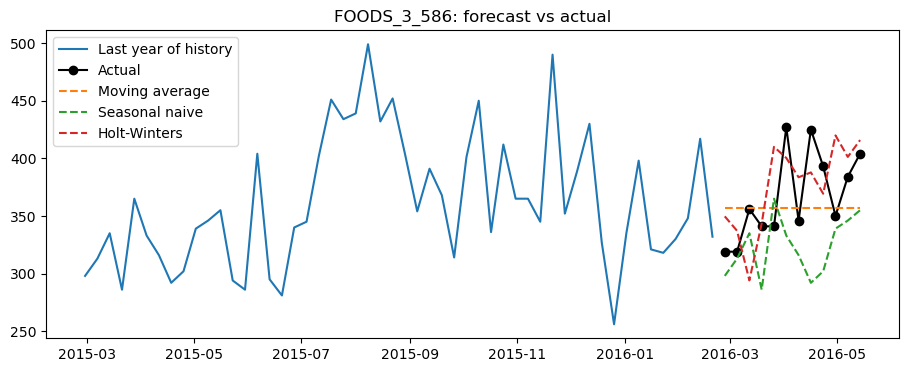

,Moving average,Seasonal naive,Holt-Winters
MAE,31.2,47.8,33.9
WAPE_%,8.5,13.0,9.2
MAPE_%,8.2,12.3,9.4
Bias_%,-2.8,-11.9,2.4
Error_SD,38.3,43.9,40.8


In [16]:
item = top_items[0]
sales_history = wide[item]
train = sales_history[:-TEST_WEEKS]
test = sales_history[-TEST_WEEKS:]

plt.figure(figsize=(11, 4))
plt.plot(train[-52:], label="Last year of history")
plt.plot(test.index, test, "k-o", label="Actual")

one_product = {}
for name in methods:
    forecast = methods[name](train, TEST_WEEKS)
    plt.plot(test.index, forecast, "--", label=name)
    one_product[name] = get_scores(test, forecast)

plt.title(item + ": forecast vs actual")
plt.legend()
plt.savefig("forecast_vs_actual.png", dpi=120, bbox_inches="tight")
plt.show()

pd.DataFrame(one_product)

## Step 15: Test every product and keep the best method
For each product: hide the last 12 weeks, run all three methods, score them, and keep the one with the lowest WAPE along with its bias, error spread and average forecast.

In [17]:
rows = []

for item in top_items:
    sales_history = wide[item]
    train = sales_history[:-TEST_WEEKS]
    test = sales_history[-TEST_WEEKS:]

    row = {"item": item, "avg_weekly_units": round(float(sales_history.mean()), 1)}
    best_name = None
    best_wape = None

    for name in methods:
        forecast = methods[name](train, TEST_WEEKS)
        scores = get_scores(test, forecast)
        row[name + " WAPE_%"] = scores["WAPE_%"]

        if best_wape is None or scores["WAPE_%"] < best_wape:
            best_name = name
            best_wape = scores["WAPE_%"]
            row["best_bias_%"] = scores["Bias_%"]
            row["error_sd"] = scores["Error_SD"]
            row["avg_forecast"] = round(sum(forecast) / len(forecast), 1)

    row["best_method"] = best_name
    row["best_WAPE_%"] = best_wape
    rows.append(row)

results = pd.DataFrame(rows).sort_values("avg_weekly_units", ascending=False)
results = results[["item", "avg_weekly_units", "Moving average WAPE_%", "Seasonal naive WAPE_%",
                   "Holt-Winters WAPE_%", "best_method", "best_WAPE_%", "best_bias_%",
                   "error_sd", "avg_forecast"]]
results

,item,avg_weekly_units,Moving average WAPE_%,Seasonal naive WAPE_%,Holt-Winters WAPE_%,best_method,best_WAPE_%,best_bias_%,error_sd,avg_forecast
0,FOODS_3_586,411.1,8.5,13.0,9.2,Moving average,8.5,-2.8,38.3,356.8
1,FOODS_3_090,342.6,9.6,34.3,24.1,Moving average,9.6,8.8,34.8,397.8
2,FOODS_3_555,253.6,13.0,23.6,11.2,Holt-Winters,11.2,-5.3,26.1,186.0
3,FOODS_3_252,206.6,15.4,17.7,10.2,Holt-Winters,10.2,5.2,26.9,233.4
4,FOODS_3_587,175.8,36.7,28.9,46.6,Seasonal naive,28.9,-11.3,60.2,158.6
5,FOODS_3_714,159.5,32.6,33.4,23.7,Holt-Winters,23.7,-23.5,19.3,110.2
6,FOODS_3_202,139.5,9.1,51.6,15.7,Moving average,9.1,0.7,19.3,183.0
7,FOODS_3_694,134.1,19.2,15.8,11.5,Holt-Winters,11.5,-10.9,15.9,129.5
8,FOODS_3_723,116.6,13.3,34.6,38.2,Moving average,13.3,13.3,12.3,134.5
9,FOODS_3_607,104.2,16.4,44.8,29.4,Moving average,16.4,-4.9,24.5,113.5


## Step 16: Forecast summary

In [18]:
print("Products won by each method:")
print(results["best_method"].value_counts())
print()
for name in methods:
    col = name + " WAPE_%"
    print(name, "| average WAPE:", round(results[col].mean(), 1), "% | median WAPE:", round(results[col].median(), 1), "%")
print()
print("Best method per product | average WAPE:", round(results["best_WAPE_%"].mean(), 1), "%")

Products won by each method:
Moving average    12
Holt-Winters       7
Seasonal naive     1
Name: best_method, dtype: int64

Moving average | average WAPE: 42.4 % | median WAPE: 26.3 %
Seasonal naive | average WAPE: 70.8 % | median WAPE: 42.0 %
Holt-Winters | average WAPE: 68.2 % | median WAPE: 32.0 %

Best method per product | average WAPE: 39.6 %


# Part 4: Inventory plan

## Step 17: Safety stock and reorder point
- **Safety stock** = Z × Error_SD × √(lead time): extra stock to cover forecast misses while waiting for an order
- **Reorder point** = (average weekly forecast × lead time) + safety stock: when stock drops to this level, place an order
- **Z = 1.65** means about a 95% chance of not running out during the lead time

In [19]:
Z = 1.65   # 95% service level

results["safety_stock"] = (Z * results["error_sd"] * (LEAD_TIME_WEEKS ** 0.5)).round(0)
results["reorder_point"] = (results["avg_forecast"] * LEAD_TIME_WEEKS + results["safety_stock"]).round(0)

plan = results[["item", "best_method", "avg_forecast", "best_WAPE_%", "error_sd", "safety_stock", "reorder_point"]]
plan

,item,best_method,avg_forecast,best_WAPE_%,error_sd,safety_stock,reorder_point
0,FOODS_3_586,Moving average,356.8,8.5,38.3,89.0,803.0
1,FOODS_3_090,Moving average,397.8,9.6,34.8,81.0,877.0
2,FOODS_3_555,Holt-Winters,186.0,11.2,26.1,61.0,433.0
3,FOODS_3_252,Holt-Winters,233.4,10.2,26.9,63.0,530.0
4,FOODS_3_587,Seasonal naive,158.6,28.9,60.2,140.0,457.0
5,FOODS_3_714,Holt-Winters,110.2,23.7,19.3,45.0,265.0
6,FOODS_3_202,Moving average,183.0,9.1,19.3,45.0,411.0
7,FOODS_3_694,Holt-Winters,129.5,11.5,15.9,37.0,296.0
8,FOODS_3_723,Moving average,134.5,13.3,12.3,29.0,298.0
9,FOODS_3_607,Moving average,113.5,16.4,24.5,57.0,284.0


## Step 18: Add prices to see the money tied up in safety stock

In [20]:
prices = pd.read_csv("sell_prices.csv")
prices = prices[prices["store_id"] == STORE]
avg_price = prices.groupby("item_id")["sell_price"].mean().reset_index()

plan = plan.merge(avg_price, left_on="item", right_on="item_id", how="left").drop(columns="item_id")
plan["safety_stock_$"] = (plan["safety_stock"] * plan["sell_price"]).round(0)

print("Total safety stock value at 95% service: $", plan["safety_stock_$"].sum())
plan

Total safety stock value at 95% service: $ 2066.0


,item,best_method,avg_forecast,best_WAPE_%,error_sd,safety_stock,reorder_point,sell_price,safety_stock_$
0,FOODS_3_586,Moving average,356.8,8.5,38.3,89.0,803.0,1.595957,142.0
1,FOODS_3_090,Moving average,397.8,9.6,34.8,81.0,877.0,1.369645,111.0
2,FOODS_3_555,Holt-Winters,186.0,11.2,26.1,61.0,433.0,1.595957,97.0
3,FOODS_3_252,Holt-Winters,233.4,10.2,26.9,63.0,530.0,1.520071,96.0
4,FOODS_3_587,Seasonal naive,158.6,28.9,60.2,140.0,457.0,2.393475,335.0
5,FOODS_3_714,Holt-Winters,110.2,23.7,19.3,45.0,265.0,1.524326,69.0
6,FOODS_3_202,Moving average,183.0,9.1,19.3,45.0,411.0,4.189504,189.0
7,FOODS_3_694,Holt-Winters,129.5,11.5,15.9,37.0,296.0,1.605887,59.0
8,FOODS_3_723,Moving average,134.5,13.3,12.3,29.0,298.0,1.374929,40.0
9,FOODS_3_607,Moving average,113.5,16.4,24.5,57.0,284.0,2.204348,126.0


## Step 19: The trade-off: higher service needs more stock
Same formula with different Z values. This shows how much extra inventory each step up in service level costs.

  service_level  safety_stock_units  safety_stock_$
0           90%                1025            1604
1           95%                1321            2067
2           98%                1642            2568
3           99%                1866            2919


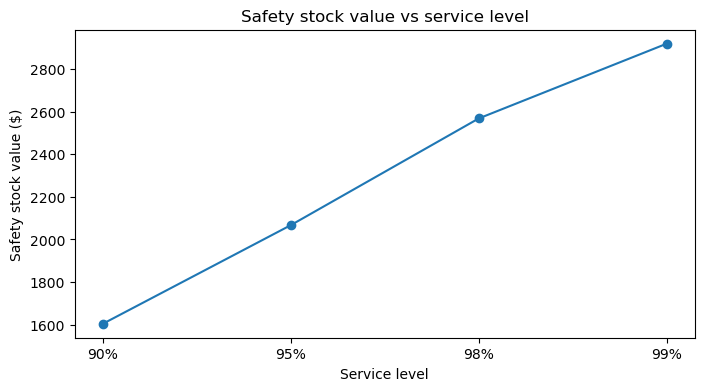

In [21]:
service_levels = {"90%": 1.28, "95%": 1.65, "98%": 2.05, "99%": 2.33}

trade_off = []
for level in service_levels:
    z = service_levels[level]
    ss_units = z * plan["error_sd"] * (LEAD_TIME_WEEKS ** 0.5)
    ss_value = (ss_units * plan["sell_price"]).sum()
    trade_off.append({"service_level": level,
                      "safety_stock_units": round(float(ss_units.sum())),
                      "safety_stock_$": round(float(ss_value))})

trade_off = pd.DataFrame(trade_off)
print(trade_off)

plt.figure(figsize=(8, 4))
plt.plot(trade_off["service_level"], trade_off["safety_stock_$"], "o-")
plt.title("Safety stock value vs service level")
plt.ylabel("Safety stock value ($)")
plt.xlabel("Service level")
plt.savefig("service_level_tradeoff.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 20: Save the results

In [22]:
results.to_csv("forecast_results.csv", index=False)
plan.to_csv("inventory_plan.csv", index=False)
trade_off.to_csv("service_level_trade_off.csv", index=False)
print("Saved forecast_results.csv, inventory_plan.csv and service_level_trade_off.csv")
print("Saved charts: decomposition.png, forecast_vs_actual.png, service_level_tradeoff.png")

Saved forecast_results.csv, inventory_plan.csv and service_level_trade_off.csv
Saved charts: decomposition.png, forecast_vs_actual.png, service_level_tradeoff.png


## Notes
- Error_SD comes from only 12 test weeks, so treat safety stock as a rough estimate. More weeks give a steadier number.
- The 2-week lead time is an assumption. Change `LEAD_TIME_WEEKS` at the top to see its effect.
- Sales of zero for several weeks can mean a stockout or a delisted product, not just low demand. Check products with very high error before trusting their plan.